# COU 07506 – Week 3 – Lab 1B: Convolution, Correlation and Difference Equations
**Name:** Iddy Omary
**Registration number:** 240242439347
**Date:** 26 November 2026
**Group:** BEng24COE-2
**Git repository:** https://github.com/iddyiom/COU07506-labs

## Pre-lab
**(a)** x(n) = {1, −1, 2}, h(n) = {2, 1, 0, 1}; the result has 3 + 4 − 1 = 6 samples.
- y(0) = 1·2 = 2
- y(1) = 1·1 + (−1)·2 = −1
- y(2) = 1·0 + (−1)·1 + 2·2 = 3
- y(3) = 1·1 + (−1)·0 + 2·1 = 3
- y(4) = (−1)·1 + 2·0 = −1
- y(5) = 2·1 = 2

→ **y(n) = {2, −1, 3, 3, −1, 2}**

**(b)** y(n) = n·x(n). Delay the input: x₁(n) = x(n − k) → y₁(n) = n·x(n − k). Delay the output: y(n − k) = (n − k)·x(n − k). Since n·x(n − k) ≠ (n − k)·x(n − k) for k ≠ 0, the system is **not time-invariant**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio
plt.rcParams["figure.figsize"] = (9, 3.5)
import time

## Task 3.1 – Convolution from the definition

In [2]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))       # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))
print("pre-lab (a) conv      :", conv([1, -1, 2], [2, 1, 0, 1]))
print("pre-lab (a) np.convolve:", np.convolve([1, -1, 2], [2, 1, 0, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]
pre-lab (a) conv      : [ 2. -1.  3.  3. -1.  2.]
pre-lab (a) np.convolve: [ 2 -1  3  3 -1  2]


In [3]:
rng = np.random.default_rng(0)
a_, b_ = rng.standard_normal(2000), rng.standard_normal(2000)
t0 = time.perf_counter(); y1 = conv(a_, b_);        t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y2 = np.convolve(a_, b_); t_np   = time.perf_counter() - t0
print("results equal:", np.allclose(y1, y2))
print(f"conv (double loop): {t_loop*1e3:10.1f} ms")
print(f"np.convolve       : {t_np*1e3:10.3f} ms   -> about {t_loop/t_np:,.0f} times faster")

results equal: True
conv (double loop):     3820.1 ms
np.convolve       :      1.585 ms   -> about 2,411 times faster


**Observation (3.1):** both functions give {1,3,6,6,4,1} and my pre-lab answer {2,−1,3,3,−1,2}. For two sequences of length 2000 the Python double loop is thousands of times slower than `np.convolve` (timings above).

## Task 3.2 – Smoothing a noisy signal by convolution

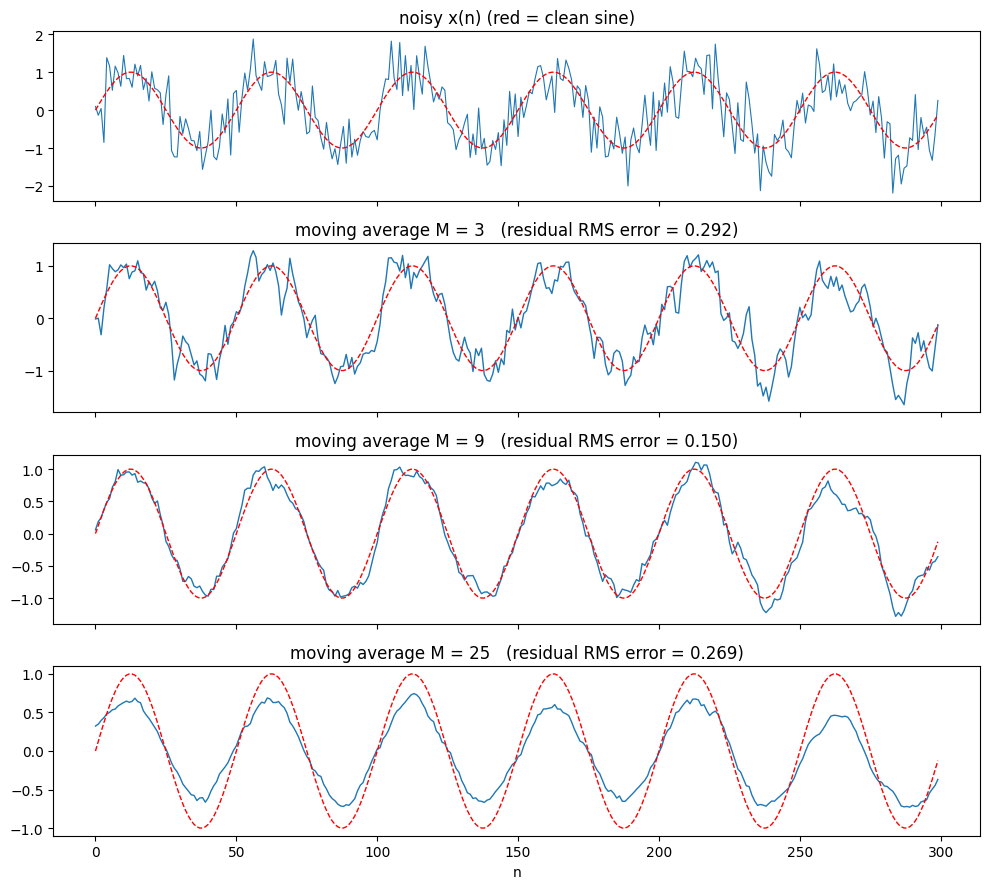

noise-only RMS of x: 0.5088166484795279


In [4]:
rng = np.random.default_rng(2)
n = np.arange(300)
clean = np.sin(2*np.pi*n/50)
x = clean + 0.5*rng.standard_normal(300)
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
axes[0].plot(n, x, lw=0.8); axes[0].plot(n, clean, "r--", lw=1); axes[0].set_title("noisy x(n) (red = clean sine)")
for ax, M_ in zip(axes[1:], [3, 9, 25]):
    h = np.ones(M_)/M_
    y = np.convolve(x, h, mode="same")
    ax.plot(n, y, lw=1); ax.plot(n, clean, "r--", lw=1)
    ax.set_title(f"moving average M = {M_}   (residual RMS error = {np.sqrt(np.mean((y-clean)**2)):.3f})")
axes[-1].set_xlabel("n")
plt.tight_layout(); plt.show()
print("noise-only RMS of x:", np.sqrt(np.mean((x-clean)**2)))

**Observation (3.2):** M = 3 removes only a little noise (output still jagged) and keeps the sine almost unchanged. M = 9 removes most noise and the sine is still clean. M = 25 is very smooth but the sine's peaks are visibly **flattened (amplitude reduced)** because the window (25 samples) is half the period (50). **Trade-off:** longer averaging → more noise reduction (noise power falls roughly as 1/M) but more distortion/smearing of the signal and the edges, and more delay. M is chosen to be much shorter than the signal's period.

## Task 3.3 – Testing linearity and time-invariance numerically

In [5]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]          # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]       # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear}  time-invariant={tinv}")

x^2             linear=False  time-invariant=True
n x(n)          linear=True  time-invariant=False
moving average  linear=True  time-invariant=True


| System | Linear | Time-invariant | Reason (handout §1.7) |
|---|---|---|---|
| y = x² | **No** | Yes | T[a·x₁ + b·x₂] = (a·x₁ + b·x₂)² contains a cross-term 2ab·x₁x₂, so superposition fails. Delaying input just delays output → TI. |
| y = n·x(n) | Yes | **No** | Scaling/adding inputs scales/adds outputs → linear. But the multiplier n changes with time: n·x(n−5) ≠ (n−5)·x(n−5) → time-varying. |
| 3-point moving average | Yes | Yes | It is a convolution with fixed h = {1/3,1/3,1/3} → LTI. |

## Task 3.4 – Finding a hidden delay with cross-correlation

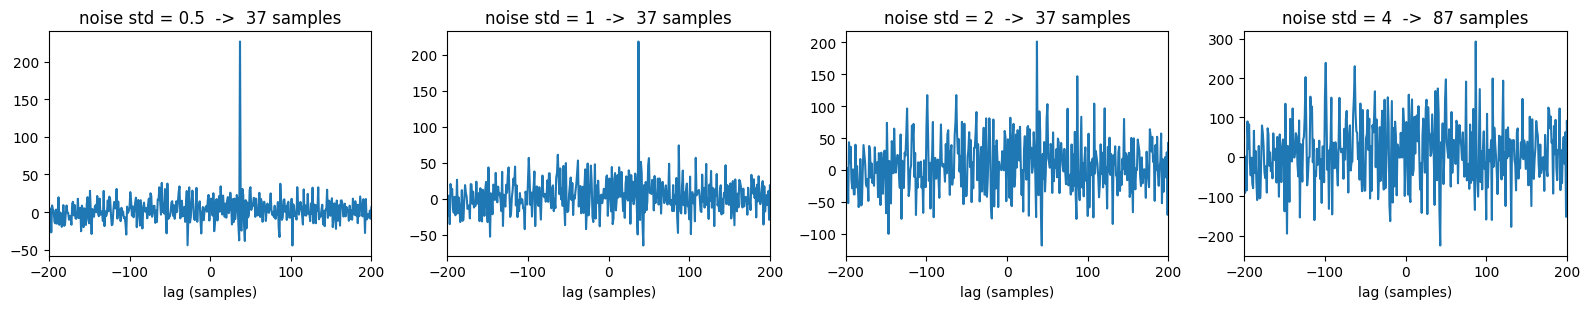

noise std | % of trials giving the correct delay (37)
    0.5   |     100 %
      1   |     100 %
      2   |     100 %


      4   |      64 %
      6   |      26 %
      8   |      11 %

estimated delay = 37 samples = 37 ms  ->  distance = 12.69 m


In [6]:
fs = 1000
true_delay = 37
def estimate(noise_std, seed=1):
    rng = np.random.default_rng(seed)
    x = rng.standard_normal(500)                  # transmitted signal
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + noise_std*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    return lags, r

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=False)
for ax, s in zip(axes, [0.5, 1, 2, 4]):
    lags, r = estimate(s)
    ax.plot(lags, r); ax.set_xlim(-200, 200); ax.set_xlabel("lag (samples)")
    ax.set_title(f"noise std = {s}  ->  {lags[np.argmax(r)]} samples")
plt.tight_layout(); plt.show()

# success rate over 200 random trials per noise level
print("noise std | % of trials giving the correct delay (37)")
for s in [0.5, 1, 2, 4, 6, 8]:
    ok = np.mean([estimate(s, seed)[0][np.argmax(estimate(s, seed)[1])] == true_delay for seed in range(100)])
    print(f"   {s:4}   |   {100*ok:5.0f} %")

lags, r = estimate(0.5)
d = lags[np.argmax(r)]
print(f"\nestimated delay = {d} samples = {d/fs*1e3:.0f} ms  ->  distance = {343*d/fs:.2f} m")

**Observation (3.4):** with noise std 0.5, 1 and 2 the correlation peak is at **37 samples** (correct). At std 4 the peak is often wrong (only about 2/3 of random trials are right) and at std ≥ 6 the estimate mostly fails: the noise (std 4–6) is 7–10× larger than the 0.6 amplitude of the delayed signal, so noise peaks in r_xy exceed the true peak. The peak height (≈ 0.6·N) is fixed while the noise floor grows with the noise level, so a longer record N improves detection.

**Distance:** delay = 37 samples / 1000 Hz = 37 ms → d = 343 m/s × 0.037 s ≈ **12.7 m**.

## Task 3.5 – Difference equation

recursion  : [1.      1.75    1.1875  0.67188 0.35547 0.18262 0.09253 0.04657 0.02336
 0.0117 ]
lfilter    : [1.      1.75    1.1875  0.67188 0.35547 0.18262 0.09253 0.04657 0.02336
 0.0117 ]
closed form: [1.      1.75    1.1875  0.67188 0.35547 0.18262 0.09253 0.04657 0.02336
 0.0117 ]
all three equal: True


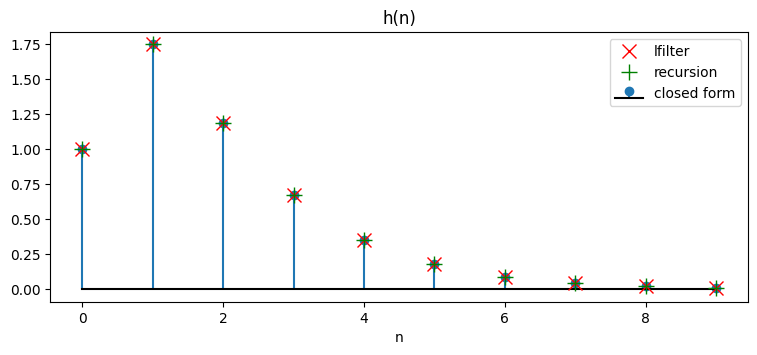

step response final value : 5.333333333333333
H(1) = sum(b)/sum(a)      : 5.333333333333333


In [7]:
N = 10
impulse = np.zeros(N); impulse[0] = 1

# 1) direct recursion  y(n) = x(n) + x(n-1) + 0.75 y(n-1) - 0.125 y(n-2)
x = impulse
h_loop = np.zeros(N)
for n in range(N):
    xn  = x[n]
    xn1 = x[n-1] if n >= 1 else 0
    y1  = h_loop[n-1] if n >= 1 else 0
    y2  = h_loop[n-2] if n >= 2 else 0
    h_loop[n] = xn + xn1 + 0.75*y1 - 0.125*y2

# 2) lfilter
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)

# 3) closed form
n = np.arange(N)
h_cf = 6*0.5**n - 5*0.25**n

np.set_printoptions(precision=5, suppress=True)
print("recursion  :", h_loop)
print("lfilter    :", h_lf)
print("closed form:", h_cf)
print("all three equal:", np.allclose(h_loop, h_lf) and np.allclose(h_lf, h_cf))

fig, ax = plt.subplots()
ax.stem(n, h_cf, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="closed form")
ax.plot(n, h_lf, "rx", ms=10, label="lfilter"); ax.plot(n, h_loop, "g+", ms=12, label="recursion")
ax.set_xlabel("n"); ax.set_title("h(n)"); ax.legend(); plt.show()

# 4) step response and final value
step = np.ones(60)
s = signal.lfilter([1, 1], [1, -0.75, 0.125], step)
print("step response final value :", s[-1])
print("H(1) = sum(b)/sum(a)      :", sum([1, 1]) / sum([1, -0.75, 0.125]))

**Observation (3.5):** the recursion, `lfilter` and the closed form h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ give identical values (h(0) = 1, h(1) = 1.75, h(2) = 1.1875, …). The step response settles to **5.333**, which equals H(1) = Σb/Σa = (1 + 1)/(1 − 0.75 + 0.125) = 2/0.375 = 5.333, as the final-value property predicts.

## Checkpoint 3
Output of Task 3.3 and the three matching impulse responses of Task 3.5: above.

## Analysis questions
**1. Why `np.convolve` is faster.** My `conv` executes L·M multiplications (each term of the double sum) one at a time in the Python interpreter, with an `if` test and indexing on every iteration. `np.convolve` performs the same ≈ L·M multiply-adds in compiled C code on contiguous arrays (no interpreter overhead), so it is orders of magnitude faster. (For very long sequences FFT-based methods, e.g. `signal.fftconvolve`, reduce the cost further to ~ N log N.)

**2. LTI systems in Task 3.3.** Only the **moving average** is LTI. x² is non-linear; n·x(n) is time-varying. Yes, this can be predicted without code: any system with a non-linear operation on x (squaring, abs, clipping) is non-linear; any system whose coefficients depend explicitly on n is time-varying; a fixed weighted sum of delayed inputs is LTI.

**3. Applications of cross-correlation in Tanzania.** (i) Locating leaks in water pipes (e.g. in DAWASA's network): two sensors on the pipe, the cross-correlation of their signals gives the time difference, from which the leak position follows. (ii) Radar/GPS: correlating the received signal with the transmitted code/pulse gives the delay and hence range, e.g. airport radar or GPS positioning in surveying and navigation.

**4. FIR or IIR? Stable?** **IIR** – the equation has feedback terms (y(n−1), y(n−2)) and h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ never becomes exactly zero (infinite length). **Stable** – both terms decay (|0.5| < 1, |0.25| < 1), so Σ|h(n)| < ∞ (poles at 0.5 and 0.25 are inside the unit circle).

## AI-use statement
I used an AI assistant (Claude) to help generate and check the code structure of this notebook. I ran the code, checked the results against the pre-lab hand calculations, and wrote/verified the observations and answers myself.